# Dummy accuracy ablation

In [1]:
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

from finsler_learning.shepplogan_pipeline.aggregate_shepplogan_results import (
    METHODS,
    collect_quality,
    collect_setup_metrics,
    merge_combined_table,
    dummy_acc_latex_table,
)

sns.set_context("notebook")
plt.rcParams["figure.figsize"] = (10, 6)


/home/tblanchard/phd/finsler_learning/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
base_path = Path("/home/tblanchard/phd/finsler_learning/results/shepplogan/runs_2026-11-11")
dummy_path = Path("/home/tblanchard/phd/finsler_learning/results/shepplogan/runs_2026-11-11_dummy_acc")
setup_paths = {False: base_path, True: dummy_path}


## Interpolation

In [3]:
df_inter, df_extra = collect_setup_metrics(
    setup_paths,
    methods=METHODS,
    setup_column="Dummy Accuracy",
)
df_quality_inter, df_quality_extra = collect_quality(
    setup_paths,
    methods=METHODS,
    setup_column="Dummy Accuracy",
)
df_inter.head()


,Geodesic Distance,Kendall Tau,Base Metric,Dummy Accuracy
0,4.412794,1.0,Euclidean,False
1,4.202264,1.0,Euclidean,False
2,6.120747,1.0,Euclidean,False
3,3.672450,1.0,Euclidean,False
4,8.126889,1.0,Euclidean,False


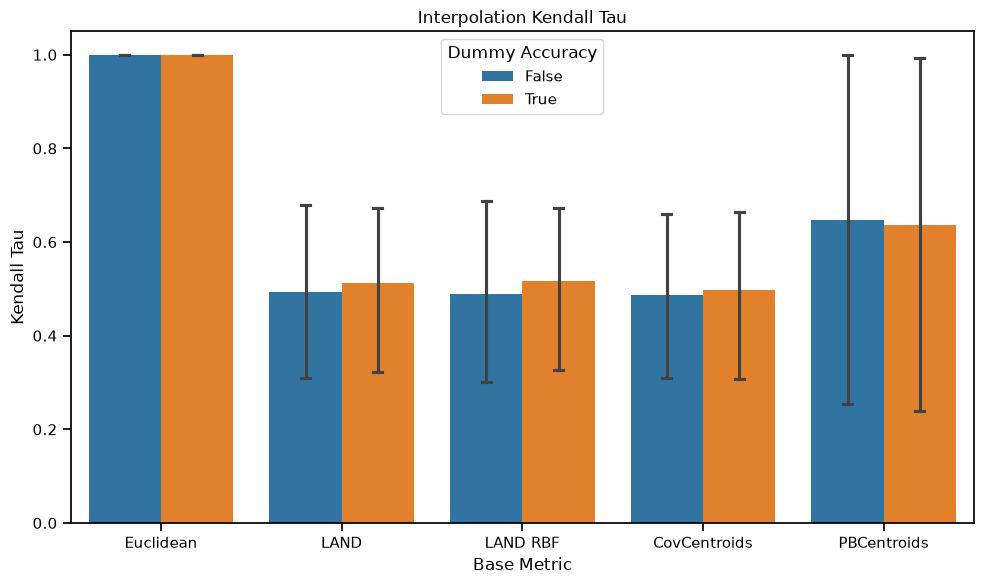

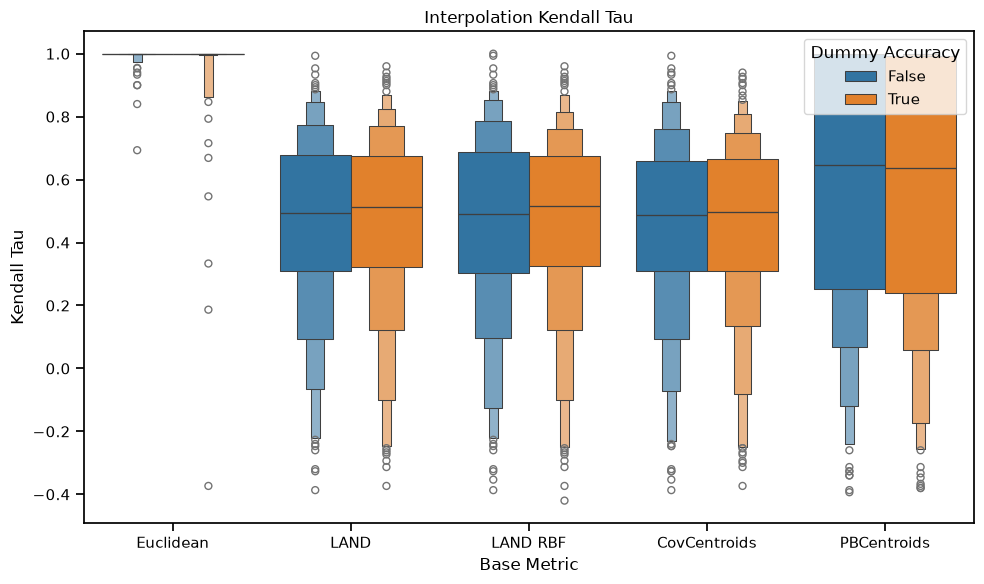

In [4]:
fig, ax = plt.subplots(1, 1, figsize=(10, 6))
sns.barplot(data=df_inter, x="Base Metric", order=[name for name, _ in METHODS], y="Kendall Tau", hue="Dummy Accuracy", estimator="median", ax=ax, errorbar=("pi", 50), capsize=0.1)
ax.set_title("Interpolation Kendall Tau")
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(1, 1, figsize=(10, 6))
sns.boxenplot(data=df_inter, x="Base Metric", order=[name for name, _ in METHODS], y="Kendall Tau", hue="Dummy Accuracy", ax=ax)
ax.set_title("Interpolation Kendall Tau")
plt.tight_layout()
plt.show()


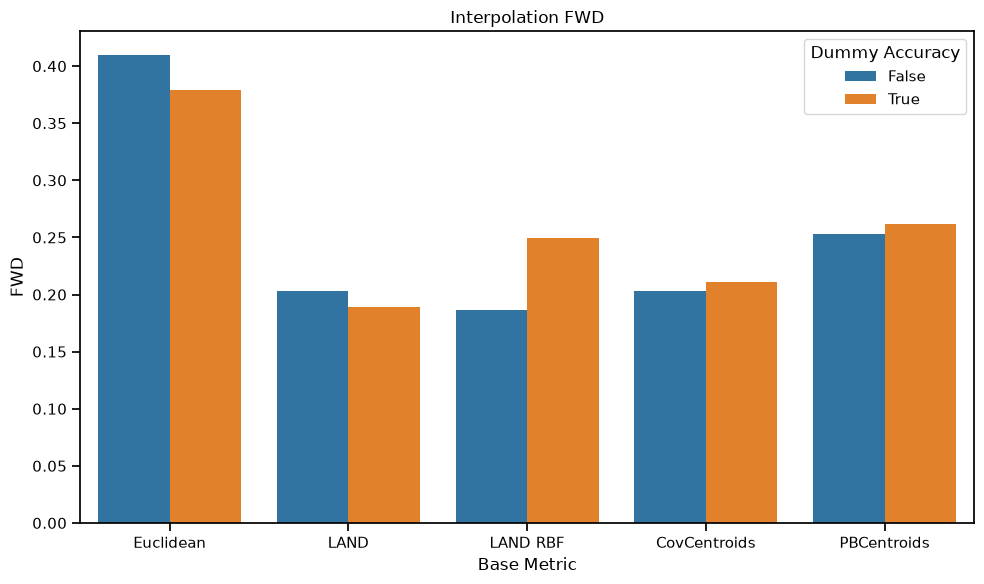

In [5]:
fig, ax = plt.subplots(1, 1, figsize=(10, 6))
sns.barplot(data=df_quality_inter, x="Base Metric", order=[name for name, _ in METHODS], y="FWD", hue="Dummy Accuracy", ax=ax, errorbar=None)
ax.set_title("Interpolation FWD")
plt.tight_layout()
plt.show()


## Extrapolation

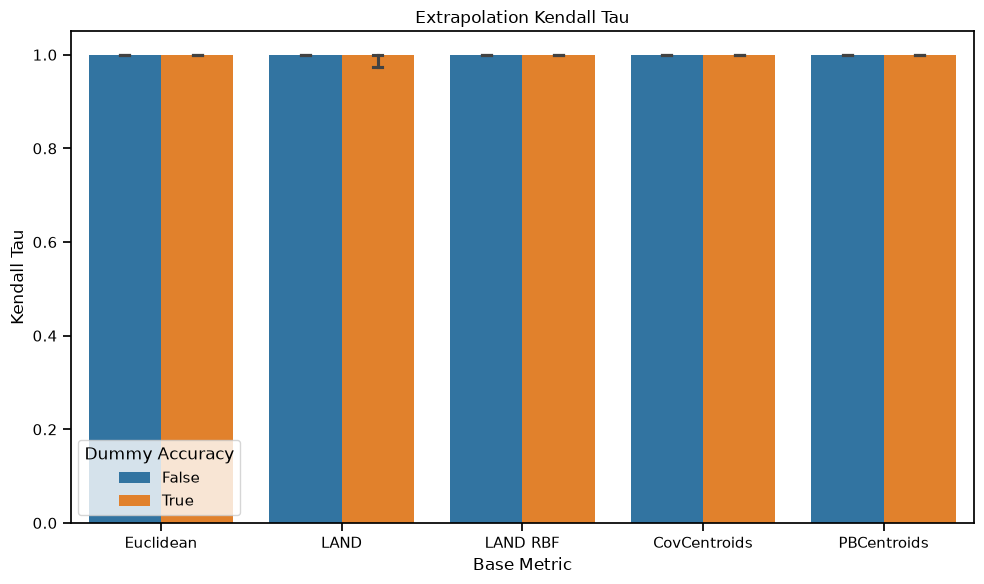

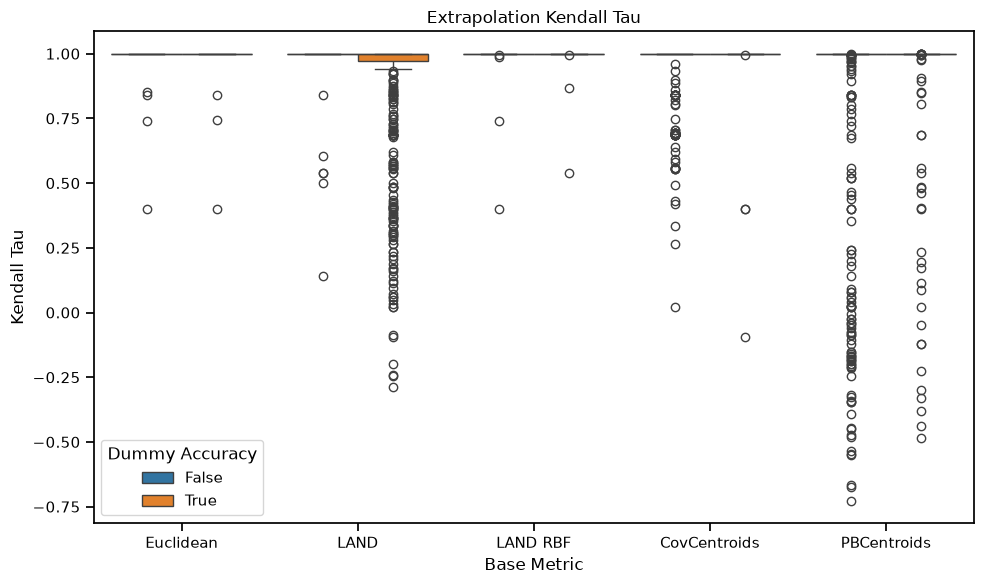

In [6]:
fig, ax = plt.subplots(1, 1, figsize=(10, 6))
sns.barplot(data=df_extra, x="Base Metric", order=[name for name, _ in METHODS], y="Kendall Tau", hue="Dummy Accuracy", estimator="median", ax=ax, errorbar=("pi", 50), capsize=0.1)
ax.set_title("Extrapolation Kendall Tau")
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(1, 1, figsize=(10, 6))
sns.boxplot(data=df_extra, x="Base Metric", order=[name for name, _ in METHODS], y="Kendall Tau", hue="Dummy Accuracy", ax=ax)
ax.set_title("Extrapolation Kendall Tau")
plt.tight_layout()
plt.show()


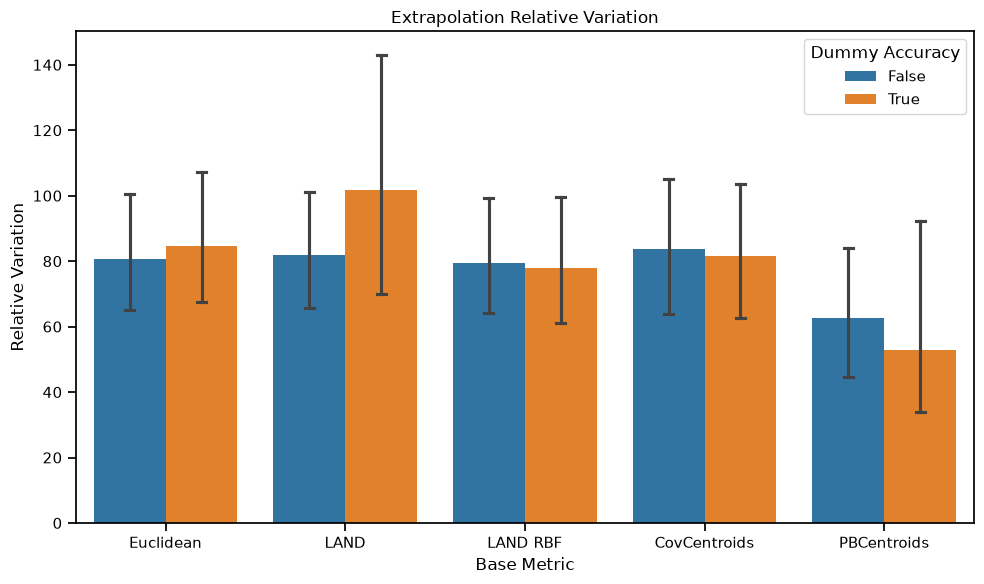

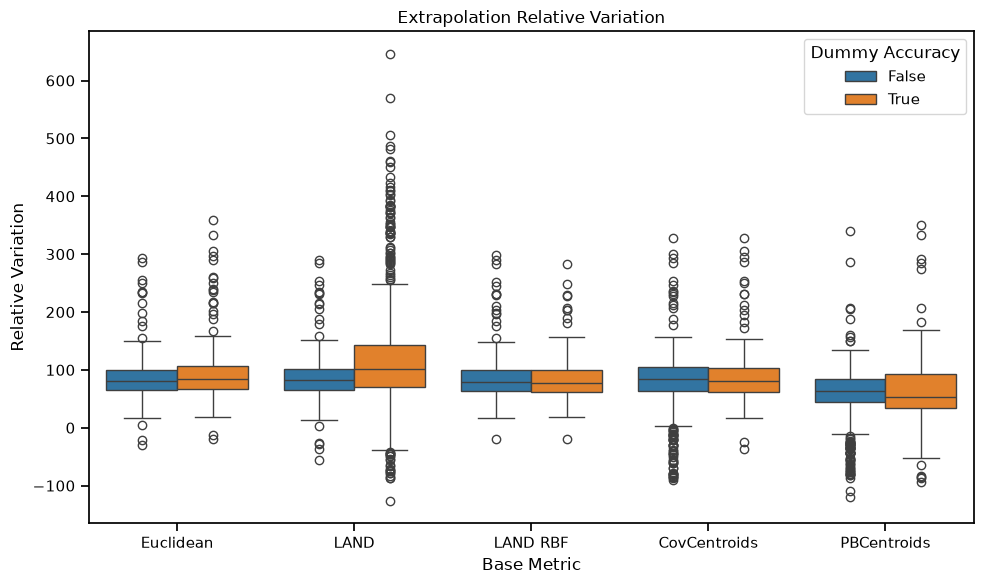

In [7]:
fig, ax = plt.subplots(1, 1, figsize=(10, 6))
sns.barplot(data=df_extra, x="Base Metric", order=[name for name, _ in METHODS], y="Relative Variation", hue="Dummy Accuracy", estimator="median", ax=ax, errorbar=("pi", 50), capsize=0.1)
ax.set_title("Extrapolation Relative Variation")
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(1, 1, figsize=(10, 6))
sns.boxplot(data=df_extra, x="Base Metric", order=[name for name, _ in METHODS], y="Relative Variation", hue="Dummy Accuracy", ax=ax)
ax.set_title("Extrapolation Relative Variation")
plt.tight_layout()
plt.show()


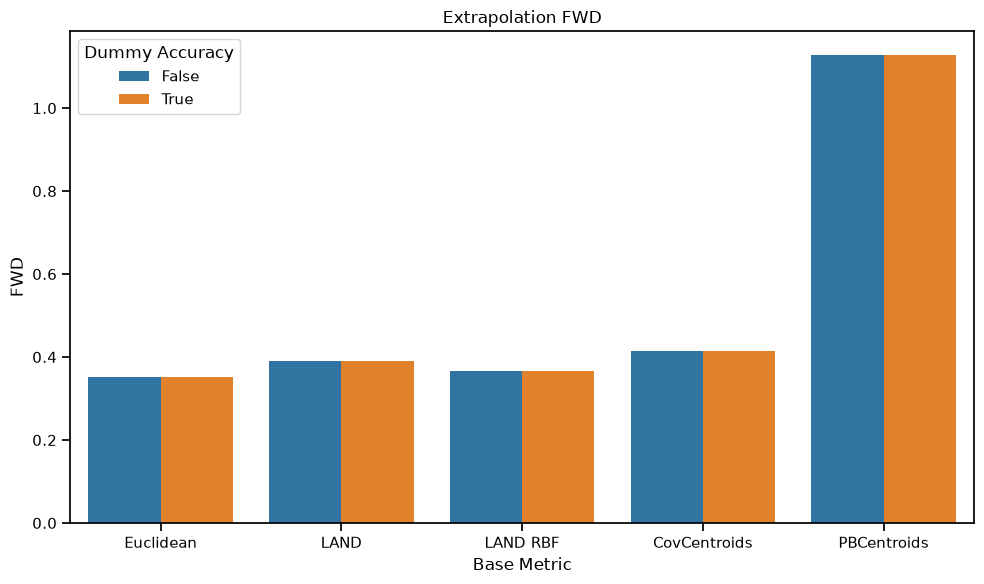

In [8]:
fig, ax = plt.subplots(1, 1, figsize=(10, 6))
sns.barplot(data=df_quality_extra, x="Base Metric", order=[name for name, _ in METHODS], y="FWD", hue="Dummy Accuracy", ax=ax, errorbar=None)
ax.set_title("Extrapolation FWD")
plt.tight_layout()
plt.show()


## Combined results

In [9]:
combined = merge_combined_table(
    df_inter,
    df_extra,
    df_quality_inter,
    df_quality_extra,
    setup_column="Dummy Accuracy",
)
combined


,Base Metric,Dummy Accuracy,Kendall Tau Median Inter,Kendall Tau IQR Inter,Kendall Tau Median Extra,Kendall Tau IQR Extra,Relative Variation Median Extra,Relative Variation IQR Extra,FWD Inter,FWD Extra
0,CovCentroids,False,0.486667,"(0.30999999999999994, 0.6599999999999998)",1.0,"(0.9999999999999998, 0.9999999999999998)",83.840446,"(63.840091705322266, 105.08301544189453)",0.203050,0.415531
1,CovCentroids,True,0.496667,"(0.30833333333333324, 0.6649999999999998)",1.0,"(0.9999999999999998, 0.9999999999999998)",81.486839,"(62.56910991668701, 103.42923164367676)",0.211292,0.415531
2,Euclidean,False,1.000000,"(0.9999999999999998, 0.9999999999999998)",1.0,"(0.9999999999999998, 0.9999999999999998)",80.795265,"(65.02141189575195, 100.50840950012207)",0.409939,0.352272
3,Euclidean,True,1.000000,"(0.9999999999999998, 0.9999999999999998)",1.0,"(0.9999999999999998, 0.9999999999999998)",84.545288,"(67.67109298706055, 107.13053703308105)",0.378918,0.352272
4,LAND,False,0.493333,"(0.30999999999999994, 0.6783333333333332)",1.0,"(0.9999999999999998, 0.9999999999999998)",81.973099,"(65.75410461425781, 101.1511173248291)",0.202665,0.391417
5,LAND,True,0.513333,"(0.32166666666666655, 0.6733333333333332)",1.0,"(0.9733333333333332, 0.9999999999999998)",101.619484,"(69.87081336975098, 143.06920623779297)",0.189381,0.391417
6,LAND RBF,False,0.490000,"(0.3016666666666666, 0.6866666666666665)",1.0,"(0.9999999999999998, 0.9999999999999998)",79.292862,"(64.0742359161377, 99.34869384765625)",0.186354,0.365346
7,LAND RBF,True,0.516667,"(0.3266666666666666, 0.6733333333333332)",1.0,"(0.9999999999999998, 0.9999999999999998)",77.814156,"(60.97206115722656, 99.56821060180664)",0.249159,0.365346
8,PBCentroids,False,0.646667,"(0.25333333333333324, 0.9995829855311987)",1.0,"(0.9999999999999998, 0.9999999999999998)",62.699211,"(44.647377014160156, 83.97538375854492)",0.252827,1.128548
9,PBCentroids,True,0.635511,"(0.23999999999999996, 0.9933333333333332)",1.0,"(0.9999999999999998, 0.9999999999999998)",52.735939,"(33.805867195129395, 92.25604820251465)",0.261477,1.128548


In [10]:
caption = (
    r"Ablation study on the amplitude parametrization on the Shepp-Logan dataset. "
    r"Here, $d=64, \alpha=5.0, \eta=0.999$, and $\zeta=0.9$. "
    r"Values are reported as median [IQR]."
)
latex = dummy_acc_latex_table(
    combined,
    caption=caption,
    label="tab:ablation_polar_form_dummy_acc",
    method_order=METHODS,
)
print(latex)


\begin{table}[ht]
\centering
\caption{Ablation study on the amplitude parametrization on the Shepp-Logan dataset. Here, $d=64, \alpha=5.0, \eta=0.999$, and $\zeta=0.9$. Values are reported as median [IQR].}
\label{tab:ablation_polar_form_dummy_acc}
\resizebox{\textwidth}{!}{%
\begin{tabular}{lcccccc}
\toprule
    & & \multicolumn{2}{c}{Interpolation} & \multicolumn{3}{c}{Extrapolation} \\
    \cmidrule(lr){3-4} \cmidrule(lr){5-7}
    Base metric & Learned $\rho_\theta$
      & Kendall Tau ($\uparrow$) & FWD ($\downarrow$)
      & Kendall Tau ($\uparrow$) & Relative Variation (\%) & FWD ($\downarrow$) \\
\midrule
    \multirow{2}{*}{Euclidean} & \xmark & $1.00\,[1.00, 1.00]$ & $0.41$ & $1.00\,[1.00, 1.00]$ & $80.80\,[65.02, 100.51]$ & $0.35$ \\
     & \checkmark & $1.00\,[1.00, 1.00]$ & $0.38$ & $1.00\,[1.00, 1.00]$ & $84.55\,[67.67, 107.13]$ & $0.35$ \\
\midrule
    \multirow{2}{*}{LAND} & \xmark & $0.49\,[0.31, 0.68]$ & $0.20$ & $1.00\,[1.00, 1.00]$ & $81.97\,[65.75, 101.15]$ & $0.39$